# 02 · EDA: análisis exploratorio (Fase 1b)
**Horizonte Clínico / SOC-IA · Unidad piloto: Cardiovascular, Hospital San José de Melipilla**

EDA = mirar los datos con tablas y gráficos **antes** de optimizar o entrenar modelos, para entender qué pasa.
Este cuaderno responde: ¿qué recintos y bloques quedan vacíos?, ¿por qué?, ¿dónde está la mayor brecha?

Entradas: `ceaa_dataset.csv`, `metadata_dataset.json`, `parametros.yaml` (los deja el cuaderno 01).
Salidas: 5 gráficos PNG en `figuras/` y `brechas_fase1.xlsx`.

In [1]:
import os, json
import numpy as np, pandas as pd, yaml
import matplotlib.pyplot as plt, seaborn as sns

try:
    from google.colab import drive
    drive.mount('/content/drive')
    BASE = '/content/drive/MyDrive/HORIZONTE_CLINICO'
except ImportError:
    BASE = os.environ.get('HC_BASE', os.path.abspath('..'))

DIR = f'{BASE}/02_fase1_datos'; FIG = f'{DIR}/figuras'
os.makedirs(FIG, exist_ok=True)
P = yaml.safe_load(open(f'{DIR}/parametros.yaml', encoding='utf-8'))
meta = json.load(open(f'{DIR}/metadata_dataset.json', encoding='utf-8'))
df = pd.read_csv(f'{DIR}/ceaa_dataset.csv', parse_dates=['fecha'])

NOTA = ('Fuente: dataset sintético con parámetros ESTÁNDAR PROVISORIOS (no son datos de Melipilla)'
        if meta['provisorio'] else 'Fuente: dataset sintético calibrado con parámetros del CDT de Melipilla')
df['ocupado'] = (df.estado_bloque == 'realizado').astype(int)
BLOQ_H = P['agenda']['bloque_min'] / 60
MESES = df.semana.nunique() / 4.345
ETQ_J = {'manana': 'Mañana', 'tarde': 'Tarde'}
COL = {'manana': '#2E75B6', 'tarde': '#ED7D31'}
plt.rcParams.update({'font.size': 10, 'axes.spines.top': False, 'axes.spines.right': False})
print(NOTA); print(df.shape, '·', df.semana.nunique(), 'semanas ·', round(MESES, 1), 'meses')

Mounted at /content/drive
Fuente: dataset sintético con parámetros ESTÁNDAR PROVISORIOS (no son datos de Melipilla)
(3840, 17) · 12 semanas · 2.8 meses


## 1. Calidad y estructura de los datos
Lo que se revisa antes de graficar: tipos, nulos esperados, duplicados y rangos.

In [2]:
calidad = pd.DataFrame({'tipo': df.dtypes.astype(str), 'nulos': df.isna().sum(), '% nulos': (df.isna().mean()*100).round(1)})
display(calidad)
print('Duplicados (fecha, bloque, recinto):', df.duplicated(['fecha', 'bloque_horario', 'ID_recinto']).sum())
print('Nulos esperados: ID_profesional (sin profesional) y duracion_real_min (bloque no realizado).')
display(df[['duracion_agendada_min', 'duracion_real_min', 'prof_disponibles', 'prof_sin_box']].describe().round(1))

,tipo,nulos,% nulos
fecha,datetime64[ns],0,0.0
semana,int64,0,0.0
dia_semana,object,0,0.0
bloque_horario,object,0,0.0
jornada,object,0,0.0
ID_recinto,object,0,0.0
tipo_recinto,object,0,0.0
ID_profesional,object,646,16.8
tipo_profesional,object,0,0.0
codigo_prestacion,object,0,0.0


Duplicados (fecha, bloque, recinto): 0
Nulos esperados: ID_profesional (sin profesional) y duracion_real_min (bloque no realizado).


,duracion_agendada_min,duracion_real_min,prof_disponibles,prof_sin_box
count,3840.0,2437.0,3840.0,3840.0
mean,27.5,31.9,1.3,0.4
std,4.3,7.3,0.8,0.6
min,20.0,11.0,0.0,0.0
25%,27.5,26.0,1.0,0.0
50%,30.0,32.0,1.0,0.0
75%,30.0,37.0,2.0,1.0
max,30.0,54.0,3.0,2.0


## 2. Gráfico 1 · Heatmap de ocupación por recinto y bloque horario
Cada celda es el % de bloques realizados en ese recinto y hora (promedio de todos los días y semanas).

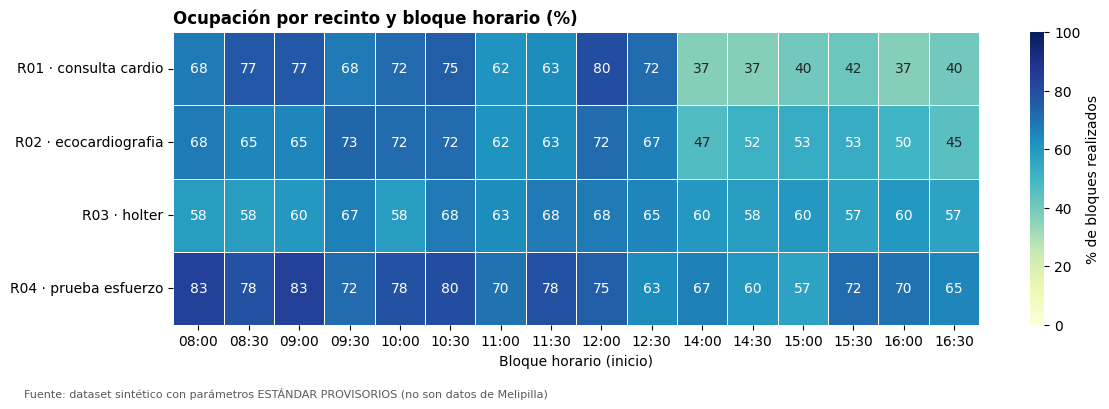

In [3]:
piv = df.pivot_table(index='ID_recinto', columns='bloque_horario', values='ocupado', aggfunc='mean') * 100
etq = df.drop_duplicates('ID_recinto').set_index('ID_recinto')['tipo_recinto']
piv_plot = piv.copy(); piv_plot.index = [f"{i} · {etq[i].replace('_', ' ')}" for i in piv.index]

fig, ax = plt.subplots(figsize=(13, 3.8))
sns.heatmap(piv_plot, annot=True, fmt='.0f', cmap='YlGnBu', vmin=0, vmax=100, linewidths=.5,
            cbar_kws={'label': '% de bloques realizados'}, ax=ax)
ax.set_title('Ocupación por recinto y bloque horario (%)', loc='left', fontweight='bold')
ax.set_xlabel('Bloque horario (inicio)'); ax.set_ylabel('')
fig.text(0.01, -0.08, NOTA, fontsize=8, color='#595959')
fig.savefig(f'{FIG}/g1_heatmap_ocupacion.png', dpi=200, bbox_inches='tight'); plt.show()

## 3. Gráfico 2 · ¿Por qué quedan bloques sin usar?
Distribución de las causas entre todos los bloques que no se realizaron.

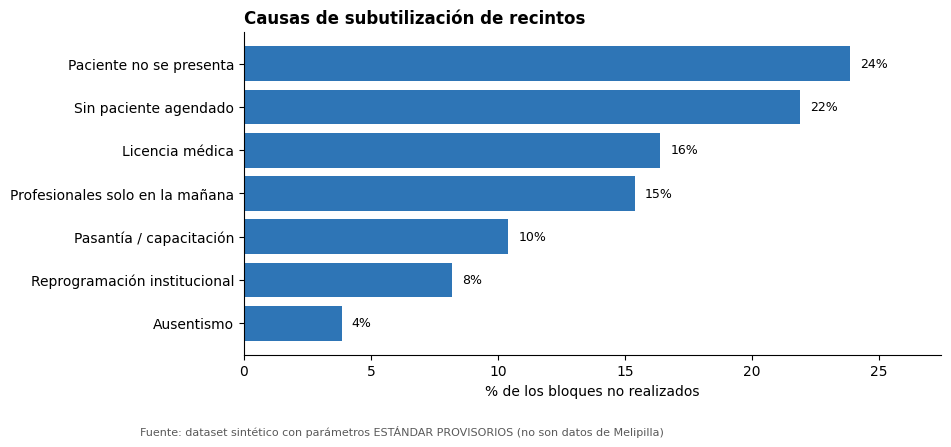

In [4]:
ETQ_CAUSA = {'sin_paciente_agendado': 'Sin paciente agendado', 'licencia': 'Licencia médica', 'pasantia': 'Pasantía / capacitación',
             'ausentismo': 'Ausentismo', 'concentracion_manana': 'Profesionales solo en la mañana',
             'sin_profesional_programado': 'Sin profesional programado', 'no_show_paciente': 'Paciente no se presenta',
             'reprogramacion_institucional': 'Reprogramación institucional'}
nr = df[df.ocupado == 0]
causas = nr.causa_no_uso.value_counts().rename_axis('causa').reset_index(name='bloques')
causas['pct'] = causas.bloques / causas.bloques.sum() * 100
causas['horas_mes'] = causas.bloques * BLOQ_H / MESES
causas['causa_txt'] = causas.causa.map(ETQ_CAUSA).fillna(causas.causa)
causas = causas.sort_values('pct')

fig, ax = plt.subplots(figsize=(9, 4.2))
ax.barh(causas.causa_txt, causas.pct, color='#2E75B6')
for y, v in enumerate(causas.pct): ax.text(v + 0.4, y, f'{v:.0f}%', va='center', fontsize=9)
ax.set_xlabel('% de los bloques no realizados'); ax.set_xlim(0, causas.pct.max() * 1.15)
ax.set_title('Causas de subutilización de recintos', loc='left', fontweight='bold')
fig.text(0.01, -0.08, NOTA, fontsize=8, color='#595959')
fig.savefig(f'{FIG}/g2_causas_no_uso.png', dpi=200, bbox_inches='tight'); plt.show()

## 4. Gráfico 3 · Brecha por tipo de recinto (horas al mes)
Horas de recinto sin usar al mes, separadas por jornada.

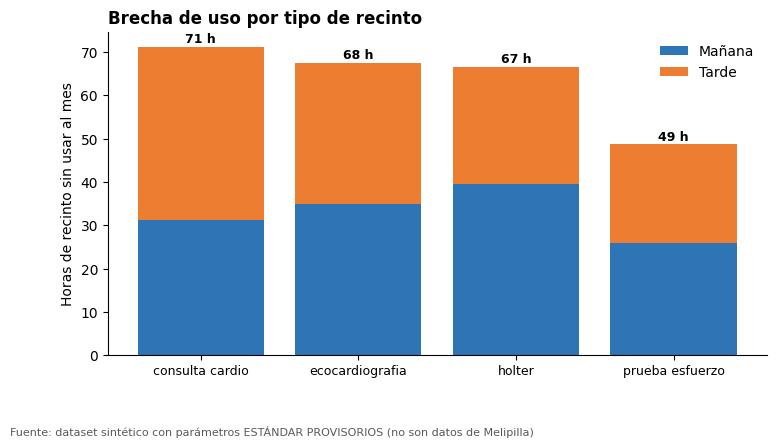

jornada,manana,tarde,total
tipo_recinto,,,
consulta_cardio,31.1,40.0,71.1
ecocardiografia,34.9,32.6,67.5
holter,39.6,27.0,66.6
prueba_esfuerzo,25.9,22.8,48.7


In [5]:
brecha = (nr.groupby(['tipo_recinto', 'jornada']).size().unstack(fill_value=0)
            .reindex(columns=['manana', 'tarde'], fill_value=0) * BLOQ_H / MESES)
brecha['total'] = brecha.sum(axis=1); brecha = brecha.sort_values('total', ascending=False)

fig, ax = plt.subplots(figsize=(8.5, 4.2))
bot = np.zeros(len(brecha))
for j in ['manana', 'tarde']:
    ax.bar(brecha.index, brecha[j], bottom=bot, color=COL[j], label=ETQ_J[j]); bot += brecha[j].values
for i, v in enumerate(brecha.total): ax.text(i, v + 1, f'{v:.0f} h', ha='center', fontsize=9, fontweight='bold')
ax.set_ylabel('Horas de recinto sin usar al mes'); ax.legend(frameon=False)
ax.set_title('Brecha de uso por tipo de recinto', loc='left', fontweight='bold')
ax.set_xticks(range(len(brecha))); ax.set_xticklabels([t.replace('_', ' ') for t in brecha.index], fontsize=9)
fig.text(0.01, -0.08, NOTA, fontsize=8, color='#595959')
fig.savefig(f'{FIG}/g3_brecha_por_recinto.png', dpi=200, bbox_inches='tight'); plt.show()
display(brecha.round(1))

## 5. Gráfico 4 · Ocupación por tipo de profesional y jornada
El Plan Maestro pide "eficiencia por especialidad"; como el piloto es una sola unidad, se compara por **tipo de profesional**.

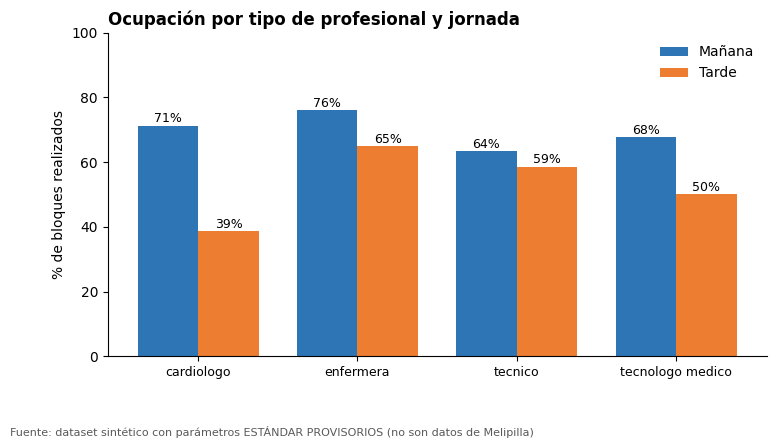

In [6]:
oc = (df.groupby(['tipo_profesional', 'jornada']).ocupado.mean().unstack().reindex(columns=['manana', 'tarde']) * 100)
x = np.arange(len(oc)); w = 0.38
fig, ax = plt.subplots(figsize=(8.5, 4.2))
for k, j in enumerate(['manana', 'tarde']):
    b = ax.bar(x + (k - .5) * w, oc[j], w, color=COL[j], label=ETQ_J[j])
    for r in b: ax.text(r.get_x() + r.get_width()/2, r.get_height() + 1, f'{r.get_height():.0f}%', ha='center', fontsize=9)
ax.set_xticks(x); ax.set_xticklabels([t.replace('_', ' ') for t in oc.index], fontsize=9); ax.set_ylim(0, 100)
ax.set_ylabel('% de bloques realizados'); ax.legend(frameon=False)
ax.set_title('Ocupación por tipo de profesional y jornada', loc='left', fontweight='bold')
fig.text(0.01, -0.08, NOTA, fontsize=8, color='#595959')
fig.savefig(f'{FIG}/g4_ocupacion_por_profesional.png', dpi=200, bbox_inches='tight'); plt.show()

## 6. Gráfico 5 · La asincronía: profesionales presentes sin recinto
Horas al mes en que había profesionales presentes **pero sin box libre** (hay un solo recinto por tipo). Es la otra cara de la brecha: capacidad humana sin dónde atender.

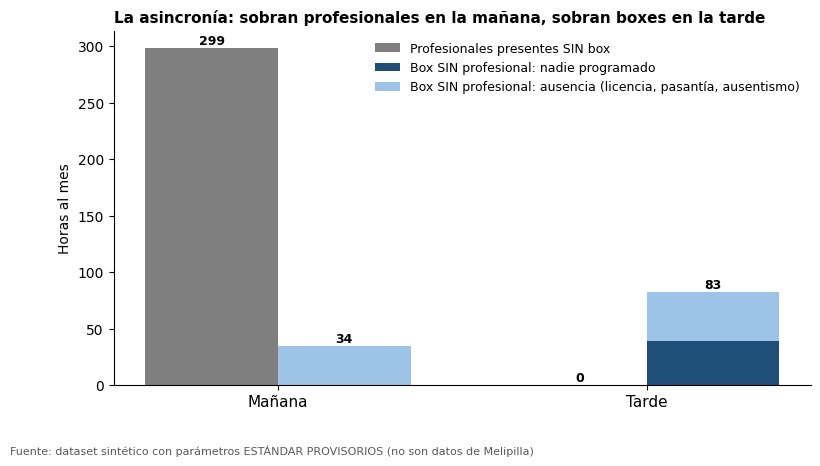

,prof_sin_box_h_mes,box_sin_prof_nadie_programado,box_sin_prof_ausencia
jornada,,,
manana,298.7,0.0,34.4
tarde,0.0,39.1,43.4


In [9]:
# Gráfico 6 · La asincronía completa: profesionales sin box (mañana) y boxes sin profesional (tarde)
ESTRUCT = ['concentracion_manana', 'sin_profesional_programado']   # nadie programado en ese bloque
AUSENCIA = ['licencia', 'pasantia', 'ausentismo']                  # había alguien programado, pero faltó

jor = ['manana', 'tarde']
prof_sin_box = (df.groupby('jornada').prof_sin_box.sum().reindex(jor, fill_value=0) * BLOQ_H / MESES)
box_sin_prof = df[df.prof_disponibles == 0]
b_estruct = (box_sin_prof[box_sin_prof.causa_no_uso.isin(ESTRUCT)].groupby('jornada').size().reindex(jor, fill_value=0) * BLOQ_H / MESES)
b_aus = (box_sin_prof[box_sin_prof.causa_no_uso.isin(AUSENCIA)].groupby('jornada').size().reindex(jor, fill_value=0) * BLOQ_H / MESES)

x = np.arange(2); w = 0.36
fig, ax = plt.subplots(figsize=(9, 4.6))
b1 = ax.bar(x - w/2, prof_sin_box, w, color='#7F7F7F', label='Profesionales presentes SIN box')
b2 = ax.bar(x + w/2, b_estruct, w, color='#1F4E79', label='Box SIN profesional: nadie programado')
b3 = ax.bar(x + w/2, b_aus, w, bottom=b_estruct, color='#9DC3E6', label='Box SIN profesional: ausencia (licencia, pasantía, ausentismo)')
for r in b1: ax.text(r.get_x() + r.get_width()/2, r.get_height() + 3, f'{r.get_height():.0f}', ha='center', fontsize=9, fontweight='bold')
for i in range(2):
    tot = b_estruct.iloc[i] + b_aus.iloc[i]
    ax.text(x[i] + w/2, tot + 3, f'{tot:.0f}', ha='center', fontsize=9, fontweight='bold')
ax.set_xticks(x); ax.set_xticklabels(['Mañana', 'Tarde'], fontsize=11)
ax.set_ylabel('Horas al mes'); ax.legend(frameon=False, fontsize=9, loc='upper right')
ax.set_title('La asincronía: sobran profesionales en la mañana, sobran boxes en la tarde', loc='left', fontweight='bold', fontsize=11)
fig.text(0.01, -0.04, NOTA, fontsize=8, color='#595959')
fig.savefig(f'{FIG}/g6_asincronia_manana_tarde.png', dpi=200, bbox_inches='tight'); plt.show()
display(pd.DataFrame({'prof_sin_box_h_mes': prof_sin_box, 'box_sin_prof_nadie_programado': b_estruct,
                      'box_sin_prof_ausencia': b_aus}).round(1))

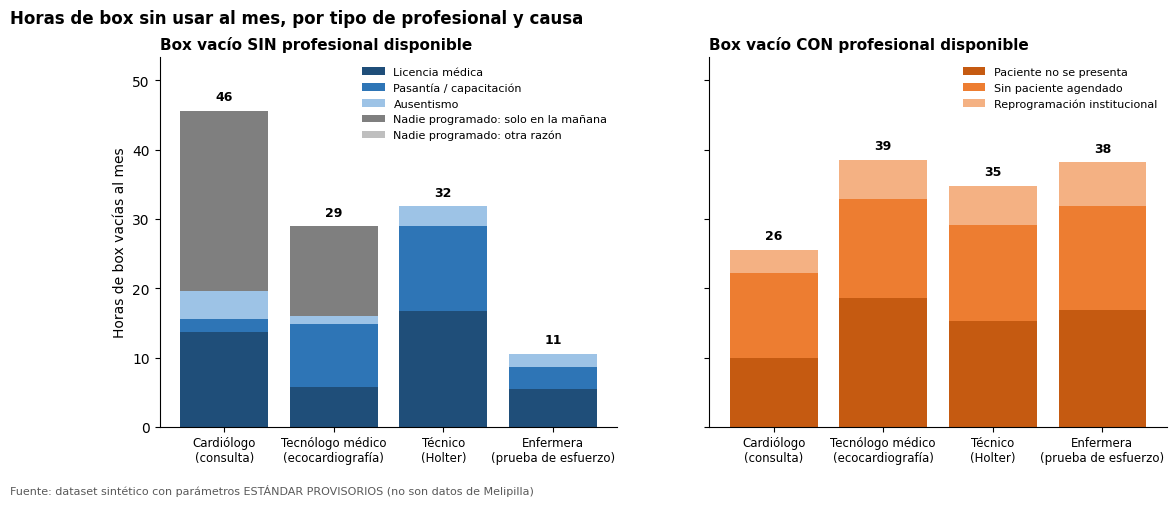

causa_no_uso,Licencia médica,Pasantía / capacitación,Ausentismo,Nadie programado: solo en la mañana,Nadie programado: otra razón,Paciente no se presenta,Sin paciente agendado,Reprogramación institucional,TOTAL h/mes
Cardiólogo (consulta),13.8,1.8,4.0,26.1,0.0,10.0,12.3,3.3,71.1
Tecnólogo médico (ecocardiografía),5.8,9.1,1.1,13.0,0.0,18.6,14.3,5.6,67.5
Técnico (Holter),16.7,12.3,2.9,0.0,0.0,15.2,13.9,5.6,66.6
Enfermera (prueba de esfuerzo),5.4,3.3,1.8,0.0,0.0,16.8,15.0,6.3,48.7


In [10]:
# Gráfico 7 · ¿Por qué queda vacío cada box? Por tipo de profesional, con y sin profesional disponible
SIN_PROF = [('licencia', 'Licencia médica', '#1F4E79'), ('pasantia', 'Pasantía / capacitación', '#2E75B6'),
            ('ausentismo', 'Ausentismo', '#9DC3E6'),
            ('concentracion_manana', 'Nadie programado: solo en la mañana', '#7F7F7F'),
            ('sin_profesional_programado', 'Nadie programado: otra razón', '#BFBFBF')]
CON_PROF = [('no_show_paciente', 'Paciente no se presenta', '#C55A11'),
            ('sin_paciente_agendado', 'Sin paciente agendado', '#ED7D31'),
            ('reprogramacion_institucional', 'Reprogramación institucional', '#F4B183')]
ETQ_TIPO = {'cardiologo': 'Cardiólogo\n(consulta)', 'tecnologo_medico': 'Tecnólogo médico\n(ecocardiografía)',
            'tecnico': 'Técnico\n(Holter)', 'enfermera': 'Enfermera\n(prueba de esfuerzo)'}

vacios = df[df.ocupado == 0]
tabla = (vacios.groupby(['tipo_profesional', 'causa_no_uso']).size().unstack(fill_value=0) * BLOQ_H / MESES)
tipos = list(ETQ_TIPO)
tabla = tabla.reindex(index=tipos, columns=[c for c, _, _ in SIN_PROF + CON_PROF], fill_value=0)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), sharey=True)
for ax, grupo, titulo in [(axes[0], SIN_PROF, 'Box vacío SIN profesional disponible'),
                          (axes[1], CON_PROF, 'Box vacío CON profesional disponible')]:
    bottom = np.zeros(len(tipos))
    for col, etq, color in grupo:
        v = tabla[col].values
        ax.bar(range(len(tipos)), v, bottom=bottom, color=color, label=etq)
        bottom += v
    for i, tot in enumerate(bottom): ax.text(i, tot + 1.5, f'{tot:.0f}', ha='center', fontsize=9, fontweight='bold')
    ax.set_xticks(range(len(tipos))); ax.set_xticklabels([ETQ_TIPO[t] for t in tipos], fontsize=8.5)
    ax.set_title(titulo, loc='left', fontweight='bold', fontsize=11)
    ax.legend(frameon=False, fontsize=8, loc='upper right')
axes[0].set_ylabel('Horas de box vacías al mes')
axes[0].set_ylim(0, tabla.sum(axis=1).max() * 0.75)
fig.suptitle('Horas de box sin usar al mes, por tipo de profesional y causa', x=0.01, ha='left', fontweight='bold', fontsize=12)
fig.text(0.01, -0.03, NOTA, fontsize=8, color='#595959')
fig.savefig(f'{FIG}/g7_causas_por_profesional.png', dpi=200, bbox_inches='tight'); plt.show()

etiquetas = {c: e for c, e, _ in SIN_PROF + CON_PROF}
res = tabla.rename(columns=etiquetas); res.index = [ETQ_TIPO[t].replace('\n', ' ') for t in res.index]
res['TOTAL h/mes'] = res.sum(axis=1)
display(res.round(1))

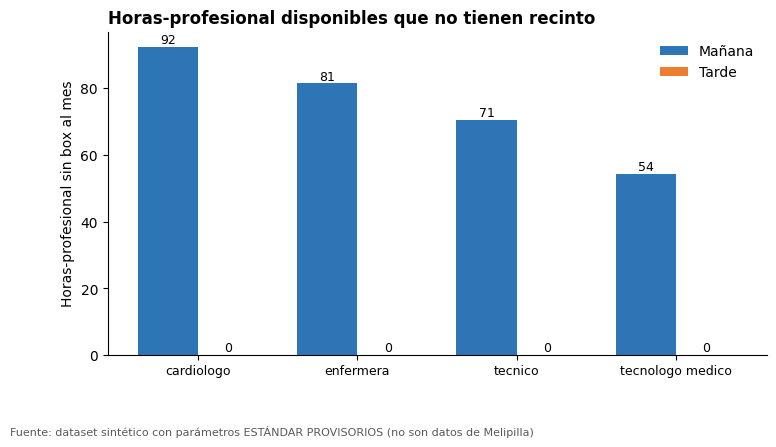

In [7]:
sb = (df.groupby(['tipo_profesional', 'jornada']).prof_sin_box.sum().unstack(fill_value=0)
        .reindex(columns=['manana', 'tarde'], fill_value=0) * BLOQ_H / MESES)
x = np.arange(len(sb)); w = 0.38
fig, ax = plt.subplots(figsize=(8.5, 4.2))
for k, j in enumerate(['manana', 'tarde']):
    b = ax.bar(x + (k - .5) * w, sb[j], w, color=COL[j], label=ETQ_J[j])
    for r in b: ax.text(r.get_x() + r.get_width()/2, r.get_height() + 1, f'{r.get_height():.0f}', ha='center', fontsize=9)
ax.set_xticks(x); ax.set_xticklabels([t.replace('_', ' ') for t in sb.index], fontsize=9)
ax.set_ylabel('Horas-profesional sin box al mes'); ax.legend(frameon=False)
ax.set_title('Horas-profesional disponibles que no tienen recinto', loc='left', fontweight='bold')
fig.text(0.01, -0.08, NOTA, fontsize=8, color='#595959')
fig.savefig(f'{FIG}/g5_profesionales_sin_box.png', dpi=200, bbox_inches='tight'); plt.show()

## 7. Resumen de brechas y top 3 de recintos → `brechas_fase1.xlsx`

In [8]:
por_recinto = (df.groupby(['ID_recinto', 'tipo_recinto'])
                 .agg(bloques=('ocupado', 'size'), realizados=('ocupado', 'sum')).reset_index())
por_recinto['ocupacion_%'] = (por_recinto.realizados / por_recinto.bloques * 100).round(1)
por_recinto['horas_sin_usar_mes'] = ((por_recinto.bloques - por_recinto.realizados) * BLOQ_H / MESES).round(1)
top3 = por_recinto.sort_values('horas_sin_usar_mes', ascending=False).head(3).reset_index(drop=True)
top3.index += 1

oc_j = df.groupby('jornada').ocupado.mean()
resumen = pd.DataFrame([
 ('Bloques analizados', len(df)), ('Semanas simuladas', df.semana.nunique()),
 ('Ocupación global (%)', round(df.ocupado.mean()*100, 1)),
 ('Ocupación mañana (%)', round(oc_j['manana']*100, 1)), ('Ocupación tarde (%)', round(oc_j['tarde']*100, 1)),
 ('Horas de recinto sin usar al mes (total)', round(brecha.total.sum(), 1)),
 ('Horas-profesional sin box al mes (total)', round(sb.values.sum(), 1)),
 ('Causa principal de no uso', causas.sort_values('pct', ascending=False).causa_txt.iloc[0]),
], columns=['indicador', 'valor'])

with pd.ExcelWriter(f'{DIR}/brechas_fase1.xlsx', engine='openpyxl') as xw:
    resumen.to_excel(xw, sheet_name='Resumen', index=False)
    por_recinto.to_excel(xw, sheet_name='Brecha_por_recinto', index=False)
    top3.to_excel(xw, sheet_name='Top3_brecha')
    causas.sort_values('pct', ascending=False)[['causa_txt', 'bloques', 'pct', 'horas_mes']].round(1).to_excel(xw, sheet_name='Causas', index=False)
    piv.round(1).to_excel(xw, sheet_name='Ocup_recinto_bloque')
    pd.DataFrame({'dato': ['Dataset provisorio', 'Fuentes', 'Nota'],
                  'valor': [str(meta['provisorio']), json.dumps(meta['fuentes'], ensure_ascii=False), NOTA]}).to_excel(xw, sheet_name='Metadatos', index=False)
    for ws in xw.book.worksheets:
        for col in ws.columns:
            ws.column_dimensions[col[0].column_letter].width = min(48, max(12, max(len(str(c.value or '')) for c in col) + 2))
display(resumen); print('\nTop 3 recintos con mayor brecha:'); display(top3)

,indicador,valor
0,Bloques analizados,3840
1,Semanas simuladas,12
2,Ocupación global (%),63.5
3,Ocupación mañana (%),69.7
4,Ocupación tarde (%),53.1
5,Horas de recinto sin usar al mes (total),254.0
6,Horas-profesional sin box al mes (total),298.7
7,Causa principal de no uso,Paciente no se presenta



Top 3 recintos con mayor brecha:


,ID_recinto,tipo_recinto,bloques,realizados,ocupacion_%,horas_sin_usar_mes
1,R01,consulta_cardio,960,567,59.1,71.1
2,R02,ecocardiografia,960,587,61.1,67.5
3,R03,holter,960,592,61.7,66.6


## 8. Lectura para la memoria (Cap. 2)
- Ejecuta todo y copia a la memoria los 5 PNG de `figuras/` más la tabla Top 3.
- Mientras los parámetros sean `ESTANDAR_PROVISORIO`, el texto debe decir que son **datos sintéticos de ejemplo**: el EDA muestra cómo se comporta el modelo, no hallazgos reales del hospital.
- Cuando lleguen los datos de Melipilla: editar `parametros.yaml`, correr 01 y luego este cuaderno, y volver a copiar gráficos y cifras.